# 02 · FashionMNIST DiT: 조건부 생성과 attention 해부

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HisameOgasahara/tmp_llm_dit/blob/main/notebooks/02_fashion_dit.ipynb)

B0 DiT로 FashionMNIST 옷 이미지를 **클래스 조건부로 생성**합니다.
- 학습 목표: **flow matching**(rectified flow). 노이즈에서 이미지로 가는 속도를 예측합니다. SD3, Flux, Qwen-Image 계열이 쓰는 방식입니다.
- 조건: 클래스 라벨. 10% 확률로 라벨을 지워서 **classifier-free guidance(CFG)**도 함께 학습합니다.
- 크기: 패치 2×2(토큰 196개), d_model 256, 6층, head 4개, 약 500만 파라미터

**보게 될 것**
1. 학습이 진행되면서 노이즈 → 윤곽 → 옷 모양으로 바뀌는 과정
2. CFG 강도에 따른 품질과 다양성 변화
3. 층마다 attention이 **가까운 패치를 보는지, 먼 패치를 보는지**

T4 기준 기본 설정 약 20~30분입니다. 빨리 확인하려면 `QUICK = True`로 바꾸세요(약 3분).

## 0. 환경 준비

In [1]:
import os
REPO_DIR = "/content/tmp_llm_dit"
if not os.path.exists(REPO_DIR):
    !git clone -q https://github.com/HisameOgasahara/tmp_llm_dit.git {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
!pip -q install -U -r requirements-colab.txt
# Colab 기본 torchao 가 최신 diffusers 와 버전이 안 맞아 import 가 깨짐 → 쓰지 않으므로 제거
!pip -q uninstall -y torchao

/content/tmp_llm_dit
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 136.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 103.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 123.0 MB/s eta 0:00:00


In [2]:
import sys, torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (런타임 유형을 GPU로 바꾸세요)")
!git log -1 --format='repo commit: %h %s'

torch 2.11.0+cu130 | GPU: Tesla T4
repo commit: f500254 Colab을 통해 생성됨


## 1. 설정과 데이터

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 208kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.1MB/s]


학습 이미지: (60000, 1, 28, 28) | 픽셀 범위: -1.0 ~ 1.0


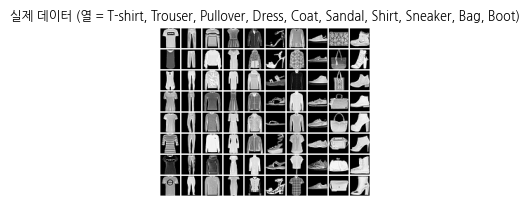

In [3]:
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그래프 한글 폰트
import torch
from miniarch.train import seed_all, get_device, count_params
from miniarch.models.dit import DiT, DiTConfig
from miniarch.tasks.fashion import CLASSES, load_fashion, train_dit, sample, to_grid
from miniarch.analysis.attention import capture_attention, grid_coords, mean_attention_distance, attention_entropy

PREFIX = "02_fashion_dit"
dev = get_device()
QUICK = False
STEPS = 1500 if QUICK else 15000
BATCH = 256
CFG = DiTConfig(in_ch=1, img_size=28, patch=2, d_model=256, n_layer=6, n_head=4, n_classes=10, class_dropout=0.1)

x_all, y_all = load_fashion(device=dev)
print("학습 이미지:", tuple(x_all.shape), "| 픽셀 범위:", x_all.min().item(), "~", x_all.max().item())

idx = torch.cat([(y_all == c).nonzero()[:8, 0] for c in range(10)])
plt.figure(figsize=(12, 2.2))
plt.imshow(to_grid(x_all[idx].view(10, 8, 1, 28, 28).transpose(0, 1).reshape(-1, 1, 28, 28), nrow=10), cmap="gray")
plt.title("실제 데이터 (열 = " + ", ".join(CLASSES) + ")", fontsize=9); plt.axis("off"); plt.show()

## 2. 학습

정해진 step마다 **같은 노이즈**로 샘플을 뽑아 둡니다(EMA 가중치 사용). 그래서 아래 3번 그림에서 같은 자리의 이미지가 학습에 따라 어떻게 변하는지 볼 수 있습니다.

In [4]:
seed_all(0)
model = DiT(CFG).to(dev)
print(f"params = {count_params(model):,}")

snap_steps = sorted({s for s in [0, 250, 500, 1000, 2000, 4000, 8000, STEPS] if s <= STEPS})
g = torch.Generator(device=dev).manual_seed(1)
snap_y = torch.arange(10, device=dev).repeat(4)                       # 클래스 0~9 × 4개
snap_noise = torch.randn(len(snap_y), 1, 28, 28, device=dev, generator=g)

hist, snaps, ema = train_dit(model, x_all, y_all, STEPS, batch=BATCH,
                             snapshot_steps=snap_steps, snap_y=snap_y, snap_noise=snap_noise)
print("최종 loss:", hist["loss"][-1])

params = 7,369,220


  0%|          | 0/15001 [00:00<?, ?it/s]

최종 loss: 0.16824687168002128


## 3. 학습 진행에 따른 샘플 변화 (행 = step, 열 = 클래스)

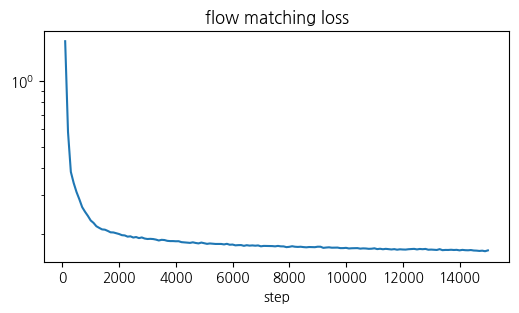

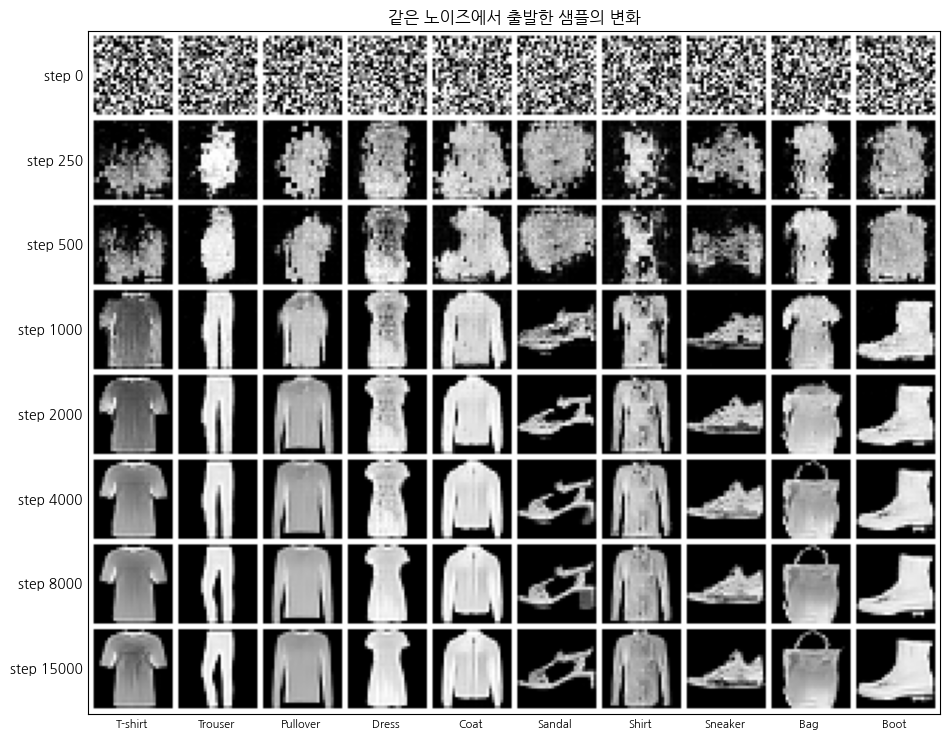

In [5]:
fig_loss = plt.figure(figsize=(6, 3))
plt.plot(hist["step"], hist["loss"]); plt.yscale("log"); plt.xlabel("step"); plt.title("flow matching loss"); plt.show()

rows = [snaps[s][:10] for s in snap_steps]                            # 각 snapshot 의 클래스별 첫 샘플
fig_prog, ax = plt.subplots(figsize=(11, 1.15 * len(rows)))
ax.imshow(to_grid(torch.cat(rows), nrow=10), cmap="gray")
ax.set_yticks([15 + 30 * i for i in range(len(rows))], [f"step {s}" for s in snap_steps])
ax.set_xticks([15 + 30 * i for i in range(10)], CLASSES, fontsize=8); ax.tick_params(length=0)
ax.set_title("같은 노이즈에서 출발한 샘플의 변화"); plt.show()

## 4. 최종 샘플과 CFG 비교

- **CFG = 1**: 조건만 주고 guidance 없음. 다양하지만 흐릿하거나 클래스가 애매할 수 있습니다.
- **CFG = 2, 4**: 클래스 특징이 뚜렷해집니다. 너무 크면 다양성이 줄고 대비가 과해집니다.

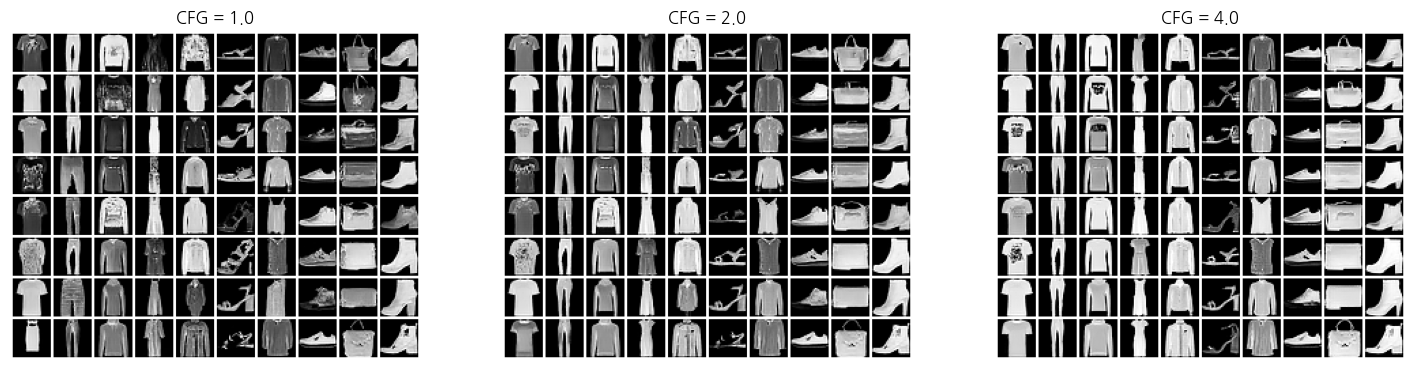

In [6]:
torch.manual_seed(2)
y8 = torch.arange(10, device=dev).repeat(8)
noise8 = torch.randn(len(y8), 1, 28, 28, device=dev)
fig_cfg, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, w in zip(axes, [1.0, 2.0, 4.0]):
    with torch.autocast("cuda", dtype=torch.float16, enabled=dev == "cuda"):
        imgs = sample(ema.model, y8, noise8, steps=50, cfg=w)
    ax.imshow(to_grid(imgs, nrow=10), cmap="gray"); ax.set_title(f"CFG = {w}"); ax.axis("off")
plt.show()

## 5. Attention 해부

실제 이미지에 노이즈를 절반 섞은 상태(t = 0.5)를 넣고, 각 층의 attention을 꺼냅니다.

- **(a) 이미지 중앙 패치가 어디를 보는가**: 층마다 head 평균 attention을 14×14 패치 격자 위에 그립니다.
- **(b) 평균 attention 거리**: 각 head가 평균적으로 몇 패치 떨어진 곳을 보는지입니다. ViT 연구에서는 보통 **앞쪽 층에 국소적인 head와 전역적인 head가 섞여 있고, 뒤쪽 층으로 갈수록 전역적**이 됩니다. DiT에서도 그런지 확인해 보세요.
- **(c) attention 엔트로피**: 낮을수록 소수의 패치에 집중합니다.

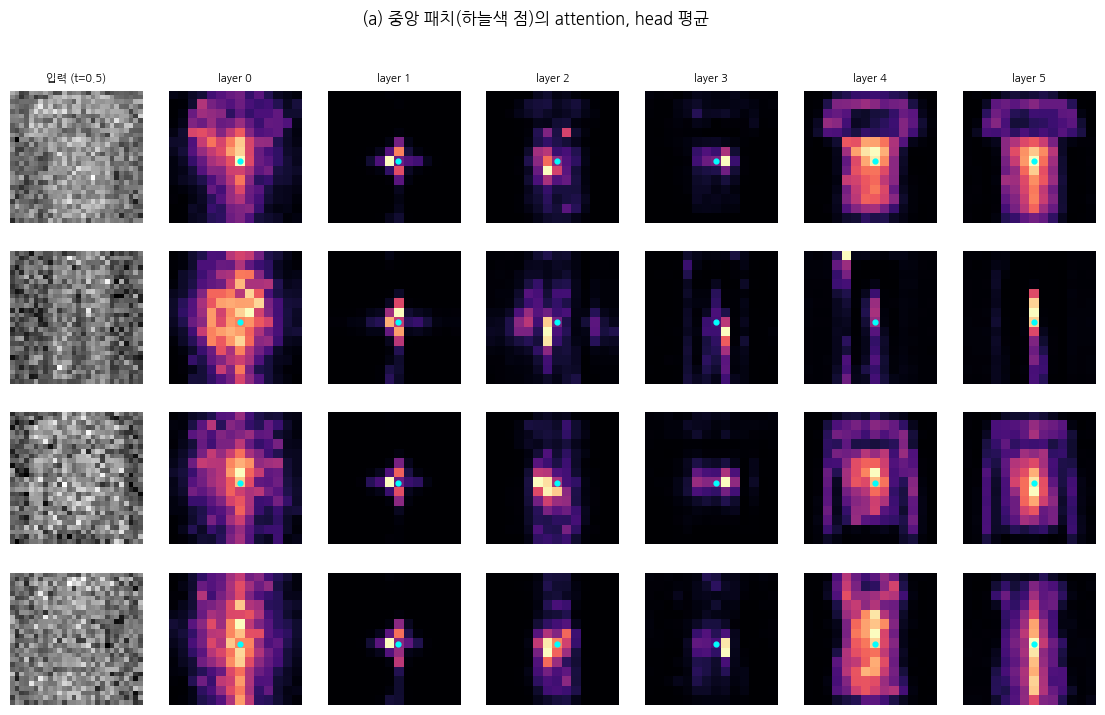

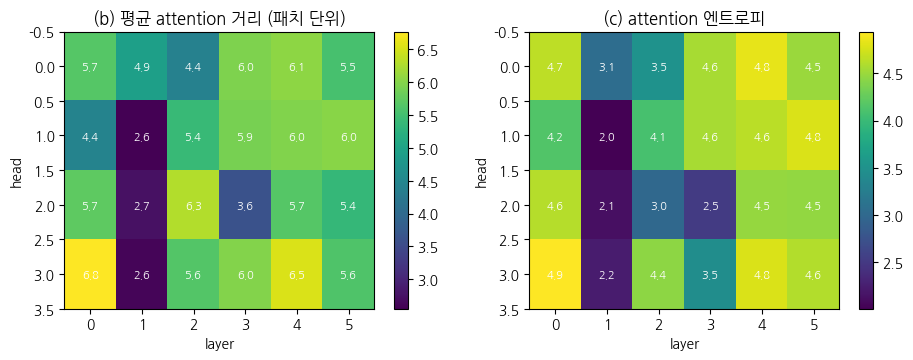

In [7]:
ex = x_all[idx[::8]][:4]                     # 클래스 0~3 실제 이미지
ey = y_all[idx[::8]][:4]
t = torch.full((len(ex),), 0.5, device=dev)
xt = 0.5 * torch.randn_like(ex) + 0.5 * ex
m = ema.model.eval()
att = capture_attention(m, lambda: m(xt, t * 1000, ey))
names = list(att)
G = CFG.img_size // CFG.patch
center = (G // 2) * G + G // 2

fig_attn, axes = plt.subplots(len(ex), len(names) + 1, figsize=(2 * (len(names) + 1), 2 * len(ex)))
for r in range(len(ex)):
    axes[r, 0].imshow(xt[r, 0].float().cpu(), cmap="gray"); axes[r, 0].set_title("입력 (t=0.5)" if r == 0 else "", fontsize=8)
    for l, n in enumerate(names):
        a = att[n][r].mean(0)[center].view(G, G)            # head 평균, 중앙 패치의 query
        axes[r, l + 1].imshow(a, cmap="magma")
        axes[r, l + 1].scatter([G // 2], [G // 2], c="cyan", s=12)
        if r == 0:
            axes[r, l + 1].set_title(f"layer {l}", fontsize=8)
for a in axes.flat:
    a.axis("off")
fig_attn.suptitle("(a) 중앙 패치(하늘색 점)의 attention, head 평균"); plt.show()

coords = grid_coords(G)
dist = torch.stack([mean_attention_distance(att[n].mean(0), coords) for n in names])   # [L, H]
ent = torch.stack([attention_entropy(att[n].mean(0)) for n in names])
fig_stats, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, M, title in [(axes[0], dist, "(b) 평균 attention 거리 (패치 단위)"), (axes[1], ent, "(c) attention 엔트로피")]:
    im = ax.imshow(M.T, cmap="viridis", aspect="auto")
    ax.set_xlabel("layer"); ax.set_ylabel("head"); ax.set_title(title)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(i, j, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=8, color="w")
    fig_stats.colorbar(im, ax=ax)
plt.show()

## 6. 결과 저장

- `results/`에 그림, loss 기록, EMA 체크포인트(`.pt`)가 저장됩니다.
- 체크포인트는 용량 때문에 git에 올라가지 않습니다(.gitignore). 보관하려면 Drive 저장을 켜세요.
- 출력이 담긴 노트북을 기록으로 남기려면 **파일 → GitHub에 사본 저장**을 쓰세요.

In [8]:
import datetime, json, shutil
STAMP = datetime.datetime.now().strftime("%Y%m%d-%H%M")
os.makedirs("results", exist_ok=True)

def save_fig(fig, name):
    path = f"results/{PREFIX}_{name}_{STAMP}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    return path

with open(f"results/{PREFIX}_{STAMP}.json", "w") as f:
    json.dump({"config": CFG.__dict__, "steps": STEPS, "batch": BATCH, "history": hist,
               "attn_distance": dist.tolist(), "attn_entropy": ent.tolist()}, f)
torch.save({"config": CFG.__dict__, "ema": ema.model.state_dict()}, f"results/{PREFIX}_ema_{STAMP}.pt")
for n, f in [("progress", fig_prog), ("cfg", fig_cfg), ("attn_center", fig_attn), ("attn_stats", fig_stats), ("loss", fig_loss)]:
    save_fig(f, n)
print([f for f in os.listdir("results") if STAMP in f])

SAVE_TO_DRIVE = False   # True 로 바꾸면 results/ 를 Drive 에도 복사 (체크포인트 포함)
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dst = "/content/drive/MyDrive/tmp_llm_dit/results"
    os.makedirs(dst, exist_ok=True)
    for f in os.listdir("results"):
        if STAMP in f:
            shutil.copy(f"results/{f}", dst)
    print("drive:", dst)

['02_fashion_dit_loss_20261015-1342.png', '02_fashion_dit_ema_20261015-1342.pt', '02_fashion_dit_20261015-1342.json', '02_fashion_dit_attn_center_20261015-1342.png', '02_fashion_dit_progress_20261015-1342.png', '02_fashion_dit_cfg_20261015-1342.png', '02_fashion_dit_attn_stats_20261015-1342.png']
